# 🐱🐶 Cat vs Dog Classification with YOLO11

This notebook implements the complete deep learning pipeline for binary pet image classification using **Ultralytics YOLO11 (`yolo11n-cls`)**:
1. **Dataset Preparation**: Stratified 85% / 15% train-validation split
2. **Model Training**: Fine-tuning YOLO11 Nano Classifier for 10 epochs
3. **Evaluation Dashboard**: Visualizing Loss curves, Top-1/Top-5 Accuracy, and Learning Rate
4. **Diagnostic Plots**: Exporting individual high-resolution 300 DPI figures
5. **Validation & Inference**: Testing the best checkpoint on validation and sample images

## 1. Imports & Global Configuration

In [4]:
import os
import shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from ultralytics import YOLO

# Plot styling
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (15, 10)

# Configuration
dataset_path = 'dataset'
classes = ['Cat', 'Dog']
print('✅ Environment and libraries ready!')

✅ Environment and libraries ready!


## 2. Dataset Preparation (Train / Validation Split)
Performs a stratified 85% train / 15% validation split into `dataset/train/` and `dataset/val/`.

In [5]:
# Verify if dataset split has already been performed
already_prepared = all(
    os.path.exists(os.path.join(dataset_path, split, cls)) and len(os.listdir(os.path.join(dataset_path, split, cls))) > 0
    for split in ['train', 'val']
    for cls in classes
)

if already_prepared:
    print('✅ Train and validation sets are already prepared. Skipping dataset re-copy.')
    for split in ['train', 'val']:
        for cls in classes:
            count = len(os.listdir(os.path.join(dataset_path, split, cls)))
            print(f'   📁 {dataset_path}/{split}/{cls}: {count} images')
else:
    valid_exts = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
    for class_name in classes:
        class_path = os.path.join(dataset_path, class_name)
        if not os.path.exists(class_path):
            raise FileNotFoundError(f"Source directory '{class_path}' not found!")

        images = [f for f in os.listdir(class_path) if f.lower().endswith(valid_exts)]
        train_imgs, val_imgs = train_test_split(images, test_size=0.15, random_state=42)

        train_dir = os.path.join(dataset_path, 'train', class_name)
        val_dir = os.path.join(dataset_path, 'val', class_name)
        os.makedirs(train_dir, exist_ok=True)
        os.makedirs(val_dir, exist_ok=True)

        print(f'Copying {len(train_imgs)} train and {len(val_imgs)} val images for {class_name}...')
        for img in train_imgs:
            shutil.copy2(os.path.join(class_path, img), os.path.join(train_dir, img))
        for img in val_imgs:
            shutil.copy2(os.path.join(class_path, img), os.path.join(val_dir, img))
    print('✅ Dataset splitting completed successfully!')

✅ Train and validation sets are already prepared. Skipping dataset re-copy.
   📁 dataset/train/Cat: 10624 images
   📁 dataset/train/Dog: 10624 images
   📁 dataset/val/Cat: 1875 images
   📁 dataset/val/Dog: 1875 images


## 3. Model Initialization & Fine-Tuning
Initializes `yolo11n-cls` pretrained on ImageNet and fine-tunes on the dataset for 10 epochs.

In [ ]:
print('\n' + '='*70)
print('🚀 ENTRAÎNEMENT DU MODÈLE YOLO11')
print('='*70 + '\n')

# Initialize the YOLO11 nano classification model
model = YOLO('yolo11n-cls')

# Train the model
results = model.train(
    data=dataset_path,
    epochs=20,
    imgsz=224,
    batch=32,
    workers=6,
    project='cat_dog_cls',
    name='yolo11',
    augment=False,
    plots=True
)

print('\n✅ Entraînement terminé !')


🚀 ENTRAÎNEMENT DU MODÈLE YOLO11

New https://pypi.org/project/ultralytics/8.4.189 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.187 🚀 Python-3.11.9 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 5806MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0

Corrupt JPEG data: 1403 extraneous bytes before marker 0xd9


       1/20     0.645G       0.51         32        224: 15% ━╸────────── 104/663 34.6it/s 3.0s<16.1s

Corrupt JPEG data: 228 extraneous bytes before marker 0xd9


       1/20     0.645G     0.2403         32        224: 57% ━━━━━━╸───── 384/663 42.1it/s 9.7s<6.6ss

Corrupt JPEG data: 2226 extraneous bytes before marker 0xd9
Corrupt JPEG data: 162 extraneous bytes before marker 0xd9


... (450 outputs left out)

Corrupt JPEG data: 214 extraneous bytes before marker 0xd9


               classes   top1_acc   top5_acc: 76% ━━━━━━━━━─── 45/59 26.2it/s 1.5s<0.5s

Corrupt JPEG data: 128 extraneous bytes before marker 0xd9


               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 59/59 27.4it/s 2.2s0.1s
                   all      0.986          1
Speed: 0.1ms preprocess, 0.2ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /home/aziz/Desktop/projet_CFN/runs/classify/cat_dog_cls/yolo11-5

✅ Entraînement terminé !


## 4. Multi-Metric Training Dashboard
Generates a comprehensive 6-panel summary dashboard visualizing loss, accuracy, and learning rate dynamics.

findfont: Failed to find font weight bold for Arial, now using 400.


✅ Chargé results.csv depuis: /home/aziz/Desktop/projet_CFN/runs/classify/cat_dog_cls/yolo11-5


/tmp/ipykernel_9949/3098679627.py:127: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/tmp/ipykernel_9949/3098679627.py:127: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/tmp/ipykernel_9949/3098679627.py:127: UserWarning: Glyph 128193 (\N{FILE FOLDER}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/tmp/ipykernel_9949/3098679627.py:129: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(dashboard_path, dpi=300)
/tmp/ipykernel_9949/3098679627.py:129: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(dashboard_path, dpi=300)
/tmp/ipykernel_9949/3098679627.py:129: UserWarning: Glyph 128193 (\N{FILE FOLDER}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(dashboard_path, dpi=300)


✅ Dashboard sauvegardé: /home/aziz/Desktop/projet_CFN/runs/classify/cat_dog_cls/yolo11-5/training_dashboard.png


/home/aziz/Desktop/projet_CFN/env/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) DejaVu Sans Mono.
  fig.canvas.print_figure(bytes_io, **kw)
/home/aziz/Desktop/projet_CFN/env/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans Mono.
  fig.canvas.print_figure(bytes_io, **kw)
/home/aziz/Desktop/projet_CFN/env/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128193 (\N{FILE FOLDER}) missing from font(s) DejaVu Sans Mono.
  fig.canvas.print_figure(bytes_io, **kw)


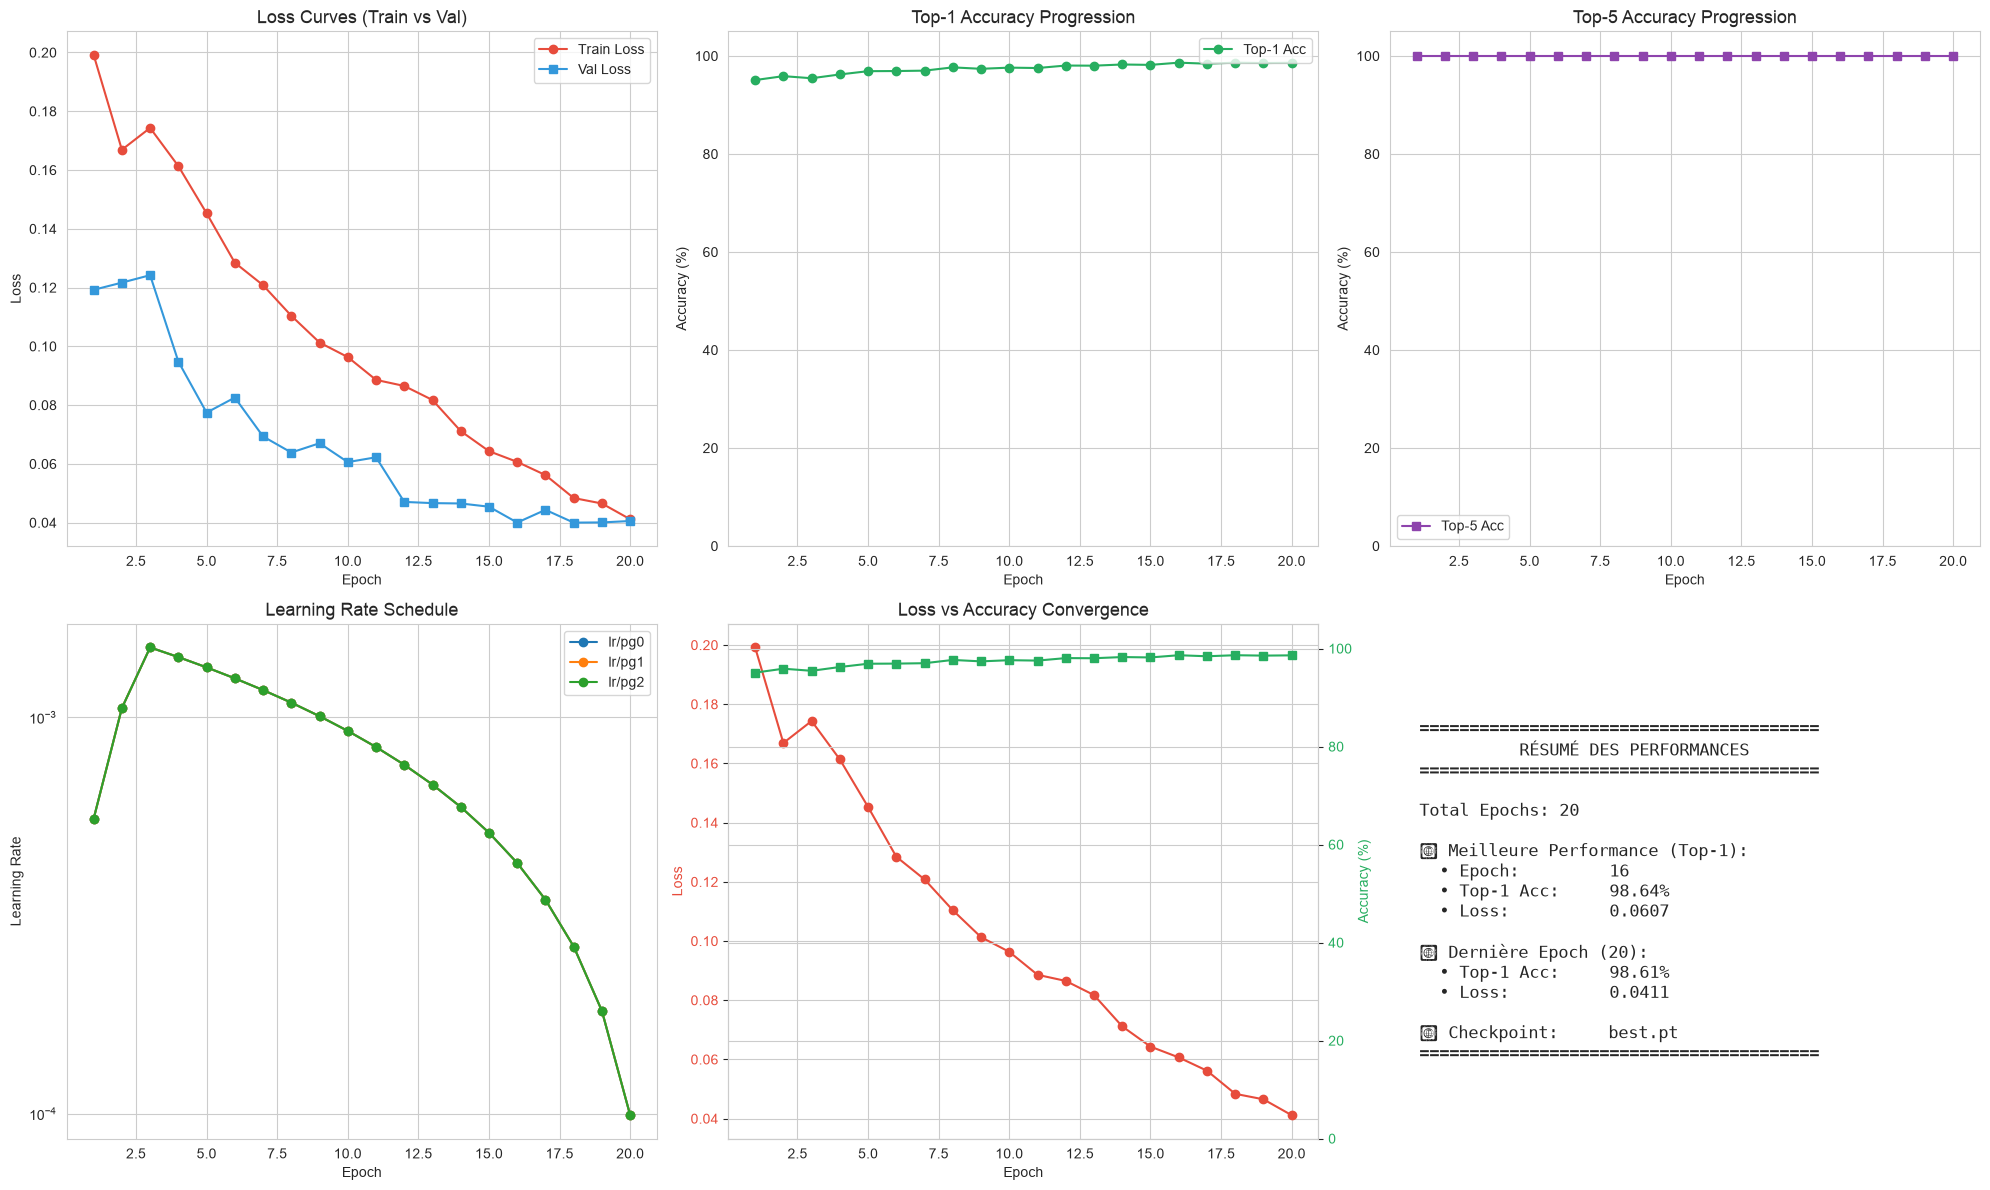

In [7]:
# ===========================
# LOCATE RESULTS DIRECTORY
# ===========================
if 'results' in locals() and hasattr(results, 'save_dir') and results.save_dir:
    results_path = Path(results.save_dir)
elif Path('runs/classify/cat_dog_cls/yolo11').exists():
    results_path = Path('runs/classify/cat_dog_cls/yolo11')
elif Path('cat_dog_cls/yolo11').exists():
    results_path = Path('cat_dog_cls/yolo11')
else:
    runs = sorted(Path('runs/classify/cat_dog_cls').glob('yolo11*'), key=os.path.getmtime)
    results_path = runs[-1] if runs else Path('cat_dog_cls/yolo11')

results_csv = results_path / 'results.csv'
if not results_csv.exists():
    raise FileNotFoundError(f"❌ results.csv introuvable dans {results_path} !")

df = pd.read_csv(results_csv)
df.columns = df.columns.str.strip()
print(f'✅ Chargé results.csv depuis: {results_path}')

# Détection des colonnes de métriques
train_loss_col = 'train/loss' if 'train/loss' in df.columns else next((c for c in df.columns if 'loss' in c.lower() and 'val' not in c.lower()), None)
val_loss_col = 'val/loss' if 'val/loss' in df.columns else next((c for c in df.columns if 'val' in c.lower() and 'loss' in c.lower()), None)
acc_col = 'metrics/accuracy_top1' if 'metrics/accuracy_top1' in df.columns else next((c for c in df.columns if 'top1' in c.lower()), None)
acc5_col = 'metrics/accuracy_top5' if 'metrics/accuracy_top5' in df.columns else next((c for c in df.columns if 'top5' in c.lower()), None)
lr_col = 'lr/pg0' if 'lr/pg0' in df.columns else next((c for c in df.columns if 'lr' in c.lower()), None)

# ===========================
# DASHBOARD PRINCIPAL (6 PANELS)
# ===========================
fig = plt.figure(figsize=(20, 12))

# 1. LOSS (Train vs Val)
ax1 = plt.subplot(2, 3, 1)
if train_loss_col:
    ax1.plot(df['epoch'], df[train_loss_col], marker='o', label='Train Loss', color='#E74C3C')
if val_loss_col:
    ax1.plot(df['epoch'], df[val_loss_col], marker='s', label='Val Loss', color='#3498DB')
ax1.set_title('Loss Curves (Train vs Val)', fontsize=13, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

# 2. TOP-1 ACCURACY
ax2 = plt.subplot(2, 3, 2)
if acc_col:
    ax2.plot(df['epoch'], df[acc_col] * 100, marker='o', color='#27AE60', label='Top-1 Acc')
    ax2.set_ylim(0, 105)
ax2.set_title('Top-1 Accuracy Progression', fontsize=13, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(True)

# 3. TOP-5 ACCURACY
ax3 = plt.subplot(2, 3, 3)
if acc5_col:
    ax3.plot(df['epoch'], df[acc5_col] * 100, marker='s', color='#8E44AD', label='Top-5 Acc')
    ax3.set_ylim(0, 105)
ax3.set_title('Top-5 Accuracy Progression', fontsize=13, fontweight='bold')
ax3.set_xlabel('Epoch')
ax3.set_ylabel('Accuracy (%)')
ax3.legend()
ax3.grid(True)

# 4. LEARNING RATE
ax4 = plt.subplot(2, 3, 4)
for lr_name in ['lr/pg0', 'lr/pg1', 'lr/pg2']:
    if lr_name in df.columns:
        ax4.plot(df['epoch'], df[lr_name], marker='o', label=lr_name)
if not any(k in df.columns for k in ['lr/pg0', 'lr/pg1', 'lr/pg2']) and lr_col:
    ax4.plot(df['epoch'], df[lr_col], marker='o', label=lr_col)
ax4.set_yscale('log')
ax4.set_title('Learning Rate Schedule', fontsize=13, fontweight='bold')
ax4.set_xlabel('Epoch')
ax4.set_ylabel('Learning Rate')
ax4.legend()
ax4.grid(True)

# 5. LOSS VS ACCURACY
ax5 = plt.subplot(2, 3, 5)
if train_loss_col:
    ax5.plot(df['epoch'], df[train_loss_col], label='Train Loss', color='#E74C3C', marker='o')
ax5.set_xlabel('Epoch')
ax5.set_ylabel('Loss', color='#E74C3C')
ax5.tick_params(axis='y', labelcolor='#E74C3C')
if acc_col:
    ax5_t = ax5.twinx()
    ax5_t.plot(df['epoch'], df[acc_col] * 100, color='#27AE60', label='Top-1 Accuracy', marker='s')
    ax5_t.set_ylabel('Accuracy (%)', color='#27AE60')
    ax5_t.tick_params(axis='y', labelcolor='#27AE60')
    ax5_t.set_ylim(0, 105)
ax5.set_title('Loss vs Accuracy Convergence', fontsize=13, fontweight='bold')
ax5.grid(True)

# 6. SUMMARY STATS
ax6 = plt.subplot(2, 3, 6)
ax6.axis('off')

final = df.iloc[-1]
best_idx = df[acc_col].idxmax() if acc_col else len(df)-1
best = df.iloc[best_idx]

loss_display = train_loss_col or 'train/loss'
summary = f"""
========================================
          RÉSUMÉ DES PERFORMANCES       
========================================

Total Epochs: {len(df)}

🏆 Meilleure Performance (Top-1):
  • Epoch:         {int(best['epoch'])}
  • Top-1 Acc:     {best[acc_col]*100:.2f}%
  • Loss:          {best[loss_display]:.4f}

📊 Dernière Epoch ({int(final['epoch'])}):
  • Top-1 Acc:     {final[acc_col]*100:.2f}%
  • Loss:          {final[loss_display]:.4f}

📁 Checkpoint:     best.pt
========================================"""
ax6.text(0.05, 0.5, summary, fontsize=12, family='monospace', va='center')

plt.tight_layout()
dashboard_path = results_path / 'training_dashboard.png'
plt.savefig(dashboard_path, dpi=300)
print(f'✅ Dashboard sauvegardé: {dashboard_path}')
plt.show()

## 5. Detailed Diagnostic Figures
Generates and saves individual high-resolution 300 DPI figures for research reports and documentation.

findfont: Failed to find font weight bold for Arial, now using 400.


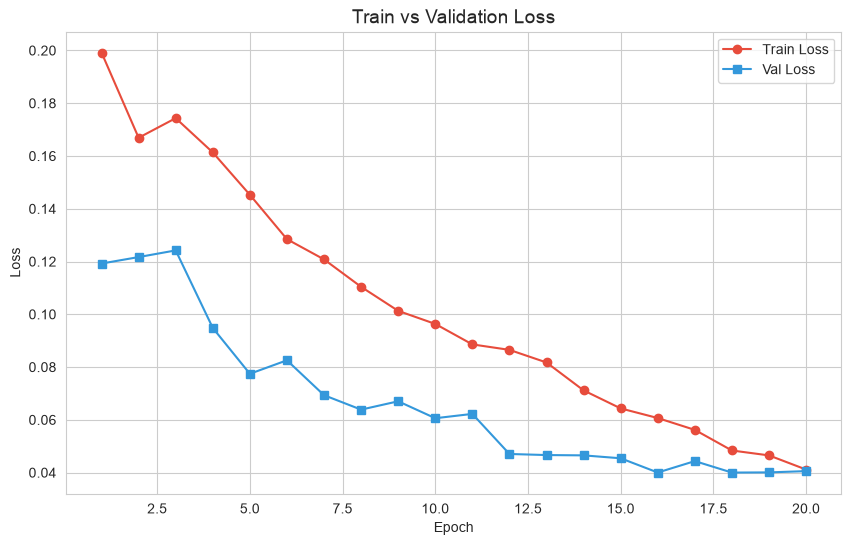

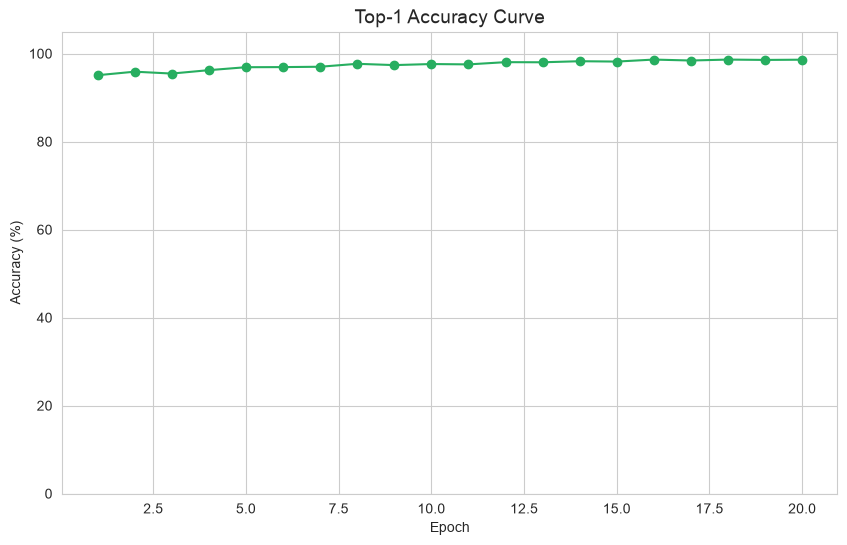

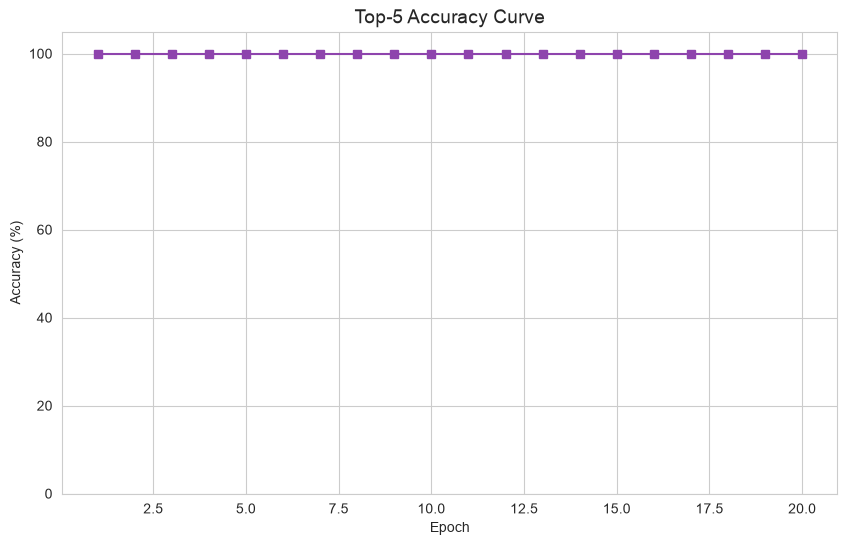

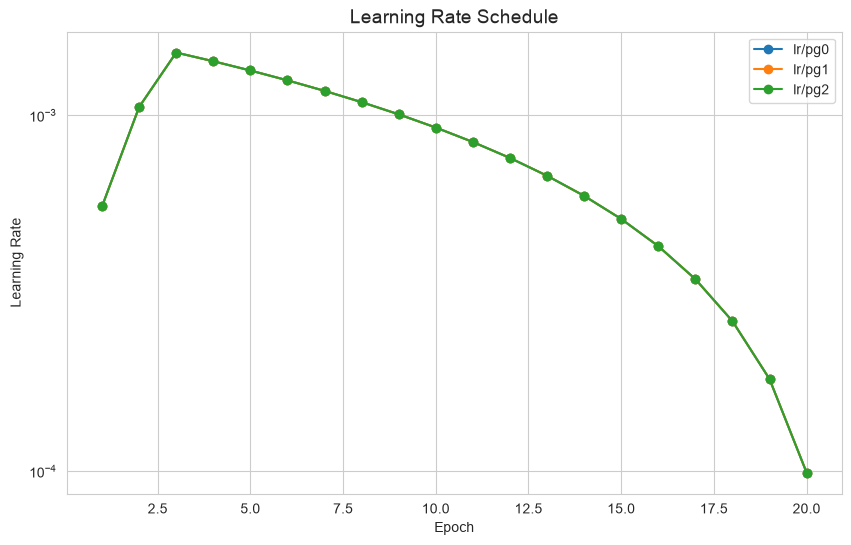

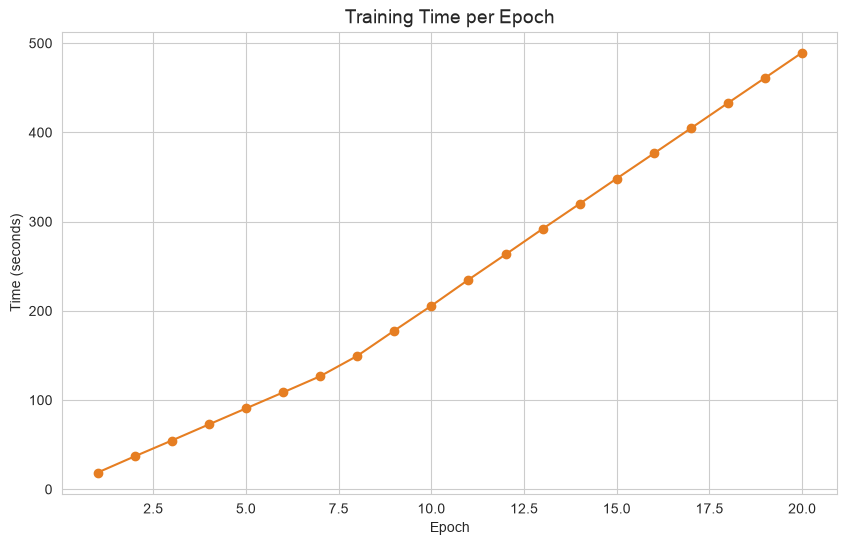

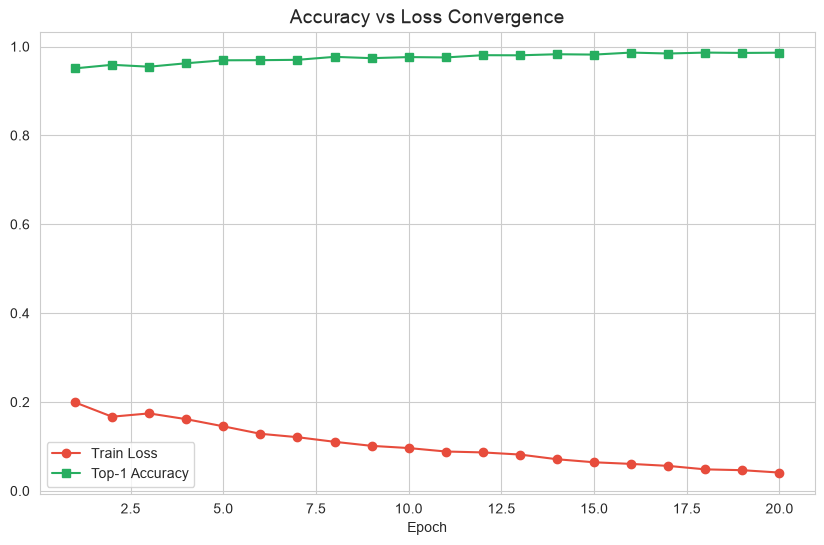

✅ Tous les graphiques ont été affichés et sauvegardés avec succès !


In [8]:
# Ensure output directory exists
results_path.mkdir(parents=True, exist_ok=True)

# 1. Train & Val Loss Curve
fig1, ax1 = plt.subplots(figsize=(10, 6))
if 'train/loss' in df.columns:
    ax1.plot(df['epoch'], df['train/loss'], label='Train Loss', marker='o', color='#E74C3C')
if 'val/loss' in df.columns:
    ax1.plot(df['epoch'], df['val/loss'], label='Val Loss', marker='s', color='#3498DB')
ax1.set_title('Train vs Validation Loss', fontsize=14, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)
plt.savefig(results_path / 'loss_curve.png', dpi=300)
plt.show()

# 2. Top-1 Accuracy Curve
fig2, ax2 = plt.subplots(figsize=(10, 6))
if 'metrics/accuracy_top1' in df.columns:
    ax2.plot(df['epoch'], df['metrics/accuracy_top1'] * 100, marker='o', color='#27AE60')
ax2.set_title('Top-1 Accuracy Curve', fontsize=14, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.set_ylim(0, 105)
ax2.grid(True)
plt.savefig(results_path / 'top1_accuracy.png', dpi=300)
plt.show()

# 3. Top-5 Accuracy Curve
fig3, ax3 = plt.subplots(figsize=(10, 6))
if 'metrics/accuracy_top5' in df.columns:
    ax3.plot(df['epoch'], df['metrics/accuracy_top5'] * 100, marker='s', color='#8E44AD')
ax3.set_title('Top-5 Accuracy Curve', fontsize=14, fontweight='bold')
ax3.set_xlabel('Epoch')
ax3.set_ylabel('Accuracy (%)')
ax3.set_ylim(0, 105)
ax3.grid(True)
plt.savefig(results_path / 'top5_accuracy.png', dpi=300)
plt.show()

# 4. Learning Rate Schedule
fig4, ax4 = plt.subplots(figsize=(10, 6))
for pg in ['lr/pg0', 'lr/pg1', 'lr/pg2']:
    if pg in df.columns:
        ax4.plot(df['epoch'], df[pg], marker='o', label=pg)
ax4.set_yscale('log')
ax4.set_title('Learning Rate Schedule', fontsize=14, fontweight='bold')
ax4.set_xlabel('Epoch')
ax4.set_ylabel('Learning Rate')
ax4.legend()
ax4.grid(True)
plt.savefig(results_path / 'learning_rate.png', dpi=300)
plt.show()

# 5. Training Time per Epoch
if 'time' in df.columns:
    fig5, ax5 = plt.subplots(figsize=(10, 6))
    ax5.plot(df['epoch'], df['time'], marker='o', color='#E67E22')
    ax5.set_title('Training Time per Epoch', fontsize=14, fontweight='bold')
    ax5.set_xlabel('Epoch')
    ax5.set_ylabel('Time (seconds)')
    ax5.grid(True)
    plt.savefig(results_path / 'time_per_epoch.png', dpi=300)
    plt.show()

# 6. Accuracy vs Loss
fig6, ax6 = plt.subplots(figsize=(10, 6))
if 'train/loss' in df.columns:
    ax6.plot(df['epoch'], df['train/loss'], label='Train Loss', marker='o', color='#E74C3C')
if 'metrics/accuracy_top1' in df.columns:
    ax6.plot(df['epoch'], df['metrics/accuracy_top1'], label='Top-1 Accuracy', marker='s', color='#27AE60')
ax6.set_title('Accuracy vs Loss Convergence', fontsize=14, fontweight='bold')
ax6.set_xlabel('Epoch')
ax6.legend()
ax6.grid(True)
plt.savefig(results_path / 'accuracy_vs_loss.png', dpi=300)
plt.show()

print('✅ Tous les graphiques ont été affichés et sauvegardés avec succès !')

## 6. Model Evaluation on Validation Set
Evaluates the best checkpoint (`best.pt`) on the validation dataset.

In [9]:
print('\n' + '='*70)
print('✅ VALIDATION DU MEILLEUR MODÈLE')
print('='*70)

weights_candidates = [
    results_path / 'weights' / 'best.pt',
    Path('runs/classify/cat_dog_cls/yolo11/weights/best.pt'),
    Path('cat_dog_cls/yolo11/weights/best.pt')
]
best_weights = next((p for p in weights_candidates if p.exists()), None)
if not best_weights:
    raise FileNotFoundError('❌ Checkpoint best.pt introuvable !')

best_model = YOLO(str(best_weights))
val_results = best_model.val(data=dataset_path)

print(f'\n🏆 Top-1 Validation Accuracy: {val_results.top1 * 100:.2f}%')
print(f'🏆 Top-5 Validation Accuracy: {val_results.top5 * 100:.2f}%')


✅ VALIDATION DU MEILLEUR MODÈLE
Ultralytics 8.4.187 🚀 Python-3.11.9 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 5806MiB)
YOLO11n-cls summary (fused): 47 layers, 1,528,586 parameters, 0 gradients, 3.2 GFLOPs
train: /home/aziz/Desktop/projet_CFN/dataset/train... found 21248 images in 2 classes ✅ 
val: /home/aziz/Desktop/projet_CFN/dataset/val... found 3750 images in 2 classes ✅ 
test: None...
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2359.3±1208.8 MB/s, size: 23.6 KB)
val: Scanning /home/aziz/Desktop/projet_CFN/dataset/val... 3742 images, 8 corrupt: 100% ━━━━━━━━━━━━ 3742/3742 2.0Git/s 0.0s
val: /home/aziz/Desktop/projet_CFN/dataset/val/Cat/10369.jpg: corrupt JPEG restored and saved
val: /home/aziz/Desktop/projet_CFN/dataset/val/Cat/11222.jpg: corrupt JPEG restored and saved
val: /home/aziz/Desktop/projet_CFN/dataset/val/Cat/12066.jpg: corrupt JPEG restored and saved
val: /home/aziz/Desktop/projet_CFN/dataset/val/Cat/140.jpg: ignoring corrupt image/label: 

Corrupt JPEG data: 128 extraneous bytes before marker 0xd9


               classes   top1_acc   top5_acc: 52% ━━━━━━────── 124/234 84.7it/s 2.0s<1.3s

Corrupt JPEG data: 214 extraneous bytes before marker 0xd9


               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 234/234 71.1it/s 3.3s0.1s
                   all      0.986          1
Speed: 0.1ms preprocess, 0.6ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /home/aziz/Desktop/projet_CFN/runs/classify/val-3

🏆 Top-1 Validation Accuracy: 98.64%
🏆 Top-5 Validation Accuracy: 100.00%


## 7. Sample Predictions
Runs inference on test images to verify classification accuracy and confidence scores.

In [10]:
print('\n' + '='*70)
print('🔍 TESTS DE PRÉDICTION')
print('='*70)

test_samples = ['test_cat.jpg', 'test_dog.jpg']

# If test images do not exist in root, pick representative samples from validation set
if not os.path.exists('test_cat.jpg') and os.path.exists('dataset/val/Cat'):
    sample_cat = os.listdir('dataset/val/Cat')[0]
    shutil.copy2(os.path.join('dataset/val/Cat', sample_cat), 'test_cat.jpg')

if not os.path.exists('test_dog.jpg') and os.path.exists('dataset/val/Dog'):
    sample_dog = os.listdir('dataset/val/Dog')[0]
    shutil.copy2(os.path.join('dataset/val/Dog', sample_dog), 'test_dog.jpg')

for img in test_samples:
    if os.path.exists(img):
        r = best_model.predict(img, verbose=False)[0]
        pred = 'Cat 🐱' if r.probs.top1 == 0 else 'Dog 🐶'
        conf = r.probs.top1conf.item()
        print(f'{img:15s} → {pred} (Confiance: {conf*100:.2f}%)')
    else:
        print(f'{img} non trouvé')

print('\n' + '='*70)
print('✅ PIPELINE TERMINÉ AVEC SUCCÈS !')
print('='*70)


🔍 TESTS DE PRÉDICTION
test_cat.jpg    → Cat 🐱 (Confiance: 100.00%)
test_dog.jpg    → Dog 🐶 (Confiance: 100.00%)

✅ PIPELINE TERMINÉ AVEC SUCCÈS !
